# Keşif

In [2]:
import numpy as np
import pandas as pd
%load_ext autoreload
%autoreload 2
import os

## Veriyi Al

In [3]:
from olist.data import Olist
data = Olist().get_data()

Olist e-ticaret platformundaki her işlem şu özelliklere sahiptir:
- satın alacak olan bir `customer_id`...
- çeşitli `product_id`...
- bir `seller_id`...
- ve bir `review_id`...
- tüm bunlar bir `order_id`'ye aittir.

## Çeşitli DataFrame'lerinizin kardinalitelerini araştırın

❓ **Kaç tane benzersiz `orders`, `reviews`, `sellers`, `products` and `customers` var ?**

In [4]:
print('siparişler :', data['orders']['order_id'].nunique())
print('yorumlar   :', data['order_reviews']['review_id'].nunique())
print('satıcılar  :', data['sellers']['seller_id'].nunique())
print('ürünler    :', data['products']['product_id'].nunique())
print('müşteriler :', data['customers']['customer_id'].nunique())
print('gerçek müşteriler:', data['customers']['customer_unique_id'].nunique())

siparişler : 99441
yorumlar   : 98410
satıcılar  : 3095
ürünler    : 32951
müşteriler : 99441
gerçek müşteriler: 96096


❓ **Sipariş başına kaç tane yorum(reviews) var? Tüm siparişler için yorum var mı?**
<details>
    <summary markdown=‘span’>İpuçları</summary>

Bu bilgiye bireysel csv dosyanızdan doğrudan erişemezsiniz. Öğrenmek için tabloları birleştirmeniz gerekir. Hangi tür birleştirme yapmanız gerektiğini düşünün.

Hangi tablolara ihtiyacınız olduğundan emin değil misiniz? Öğrenmek için ERD'nize geri dönün.

Yorum sayısını öğrenmek için: `order_id` başına yorum sayısını sayın ve bir histogram çizin. Pandas serisinde `.hist()` kullanabilirsiniz.
</details>

review_id
0      768
1    98126
2      543
3        4
Name: count, dtype: int64


<Axes: >

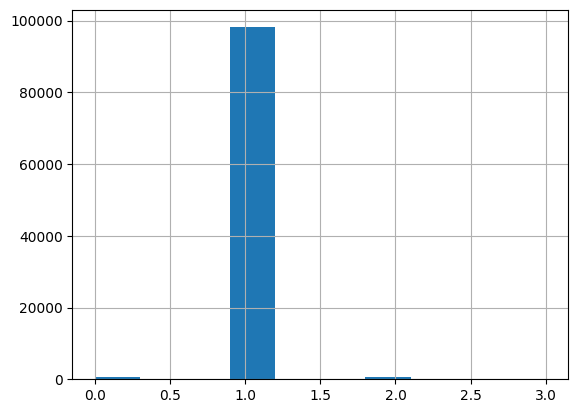

In [6]:
orders_reviews = data['orders'].merge(data['order_reviews'], on='order_id', how='left')

reviews_per_order = orders_reviews.groupby('order_id')['review_id'].count()

print(reviews_per_order.value_counts().sort_index())
reviews_per_order.hist()

🧪 **Test your code below**

Yorum eksik olan siparişlerin sayısını `int` olarak `n_missing_reviews` adlı bir değişkende saklayın.

In [ ]:
# YOUR CODE HERE

In [ ]:
from nbresult import ChallengeResult

result = ChallengeResult('exploratory',
    n=n_missing_reviews
)
result.write()
print(result.check())